# Ayudantía Nº 7: Test de hipótesis
### χ², test exacto de Fisher, *t* de Student y ANOVA

**Objetivo:** formular hipótesis, seleccionar la prueba según las variables, revisar sus supuestos e interpretar resultados a partir de la encuesta de estudiantes de Antropología.


## Preparación de la ayudantía

1. Sube `base_antropologia_limpia.xlsx` al panel **Archivos** de Google Colab
2. Ejecuta las celdas en orden
3. Observa las salidas de cada análisis y responde los ejercicios

In [ ]:
#Istalar y cargar paquetes
paquetes <- c("dplyr", "ggplot2", "scales", "readxl")
faltantes <- paquetes[!vapply(paquetes, requireNamespace, logical(1), quietly = TRUE)]
if (length(faltantes) > 0) install.packages(faltantes, repos = "https://cloud.r-project.org")
library(dplyr)
library(ggplot2)
library(scales)


In [ ]:
# Importar base de datos
base <- readxl::read_excel("/content/base_antropologia_limpia.xlsx")


## ¿Qué son los **test de hipótesis?**

Hasta ahora hemos descrito los datos con frecuencias, gráficos y promedios. En esta ayudantía utilizaremos **pruebas de hipótesis** para evaluar si las diferencias o asociaciones observadas aportan evidencia estadística contra una hipótesis inicial.

* Evaluar si las diferencias o asociaciones que encontramos podrían explicarse por el azar o si **existe suficiente evidencia estadística para sostener que hay una diferencia o asociación**.

### Para ello se construyen **hipótesis que buscamos probar**: aceptar o rechazar

- **Hipótesis nula (H₀):** plantea que no existe asociación entre las variables o bien que las medias de los grupos son iguales

  - **Hipótesis alternativa (H₁):** plantea que existe una asociación o una diferencia entre medias

Trabajaremos con un *nivel de significación* **α = 0,05**.
- Si el **valor p** es menor que 0,05, rechazamos H₀, lo que significa que existe suficiente evidencia estadística para rechazar la hipótesis nula y respaldar la hipótesis alternativa  

- Si es igual o mayor, no rechazamos H₀, lo que **no demuestra** que H₀ sea verdadera. El valor p se interpreta suponiendo que H₀ es cierta, no como la probabilidad de que H₀ sea verdadera

#### En síntesis, debemos fijarnos en si el valor p es mayor o menor a 0,05

## **Variables independientes y dependientes**, ejemplos de la encuesta

| Pregunta | Variable independiente, agrupación o explicación | Variable dependiente o resultado | Hipótesis nula |
|:--|:--|:--|:--|
| ¿La satisfacción académica se distribuye de manera distinta según identidad de género? | `identidad_genero_r`, categórica | `ea_05_satisfaccion_rendimiento_academico_r`, categórica | Ambas variables son independientes, no existe asociación |


**Importante:** llamar independiente o dependiente a una variable sirve para organizar la pregunta, **no demuestra causalidad**. En χ² y Fisher la asociación es simétrica, por lo que la prueba no establece una dirección causal.


### 1.1. Reconocer el **tipo de variable** antes de elegir la prueba

Las variables **categóricas** clasifican respuestas en grupos, por ejemplo, *identidad de género* o *satisfacción académica*. Las variables **numéricas** contienen valores sobre los que tiene sentido calcular medias, como `ma_02`.


In [13]:
# Inspeccionamos clases y categorías antes de decidir la prueba
sapply(base[c("identidad_genero_r", "ea_05_satisfaccion_rendimiento_academico_r",
              "ea_03_descripcion_carga_academica", "ea_04_notas_ultimo_semestre", "ma_02")], class)

table(base$identidad_genero_r, useNA = "ifany")
table(base$ea_05_satisfaccion_rendimiento_academico_r, useNA = "ifany")
table(base$ea_04_notas_ultimo_semestre, useNA = "ifany")
table(base$ma_02, useNA = "ifany")

identidad_genero_r 
                               "character" 
ea_05_satisfaccion_rendimiento_academico_r 
                               "character" 
         ea_03_descripcion_carga_academica 
                               "character" 
               ea_04_notas_ultimo_semestre 
                                 "numeric" 
                                     ma_02 
                                 "numeric"


         Hombre cisgenero           Mujer cisgenero Persona de genero diverso 
                       42                        84                        21 


Insatisfecho   Satisfecho         <NA> 
          61           73           13 


 4.5  4.6  4.8  4.9    5  5.1  5.2  5.3  5.4  5.5  5.6  5.7  5.8  5.9    6  6.1 
   3    1    1    2    6    4    4    5    6   13    7    5    9    7   20    3 
 6.2  6.3  6.4  6.6  6.7 <NA> 
   8    5    5    1    1   31 


 1  2  3  4  5  6  7  8  9 10 
12  5  9 15 26 14 26 20  8 12 


- `class()` permite verificar si una variable se almacena como numérica o categórica. `table()` muestra las categorías efectivamente observadas. Para χ² y Fisher se cruzan dos variables categóricas; para *t*/ANOVA se requiere una variable numérica y otra que defina grupos.

## **Chi cuadrado χ² y test exacto de Fisher**: hipótesis con variables categóricas

### 2.1. ¿Qué queremos investigar?

Ambas pruebas evalúan si **dos variables categóricas están asociadas**. En este ejemplo, preguntamos si **la distribución de la satisfacción académica cambia respecto de la identidad de género**.

#### ¿La distribución de la satisfacción académica cambia respecto de la identidad de género?

- **H₀:** identidad de género y satisfacción académica son independientes.
- **H₁:** existe asociación entre ambas variables.

### 2.2. Supuestos y elección de prueba

**χ² de independencia:** requiere
- 1. **Oservaciones independientes:** cada observación debe ser independiente de las demás. En nuestro caso, cada estudiante debe aportar una sola observación a la tabla de contingencia o responder una sola vez la encuesta
- 2. **Categorías mutuamente excluyentes:** cada estudiante debe pertenecer a una sola categoría de cada variable analizada, no puede estar contabilizado simultáneamente en dos categorías distintas
- 3. **Recuentos de casos, no porcentajes como entrada:** debemos aplicar la prueba utilizando las frecuencias absolutas

Para la aproximación en χ², la Clase 10 propone revisar las **frecuencias esperadas**, idealmente ninguna menor que 1 y al menos el 80 % de las celdas con frecuencia esperada de 5 o más.

**Fisher:** también requiere
- 1. **Observaciones independientes**
- 2. **Una tabla de recuentos categóricos:** debemos trabajar con dos variables categóricas organizadas en una tabla de contingencia que contenga frecuencias absolutas, es decir, cantidades reales de casos y no porcentajes

Es una alternativa cuando las **frecuencias esperadas son pequeñas**, porque no depende de la misma aproximación asintótica que χ². En esta ayudantía seguiremos la regla práctica de la Clase 10, revisar los valores esperados antes de decidir.

### Debemos observar entonces las frecuencias

- **Frecuencia observada:** cantidad real de casos en una celda

- **Frecuencia esperada:** cantidad que esperaríamos si las variables fueran independientes

### Diferencias entre frecuencia observada y frecuencia esperada

| Característica | Frecuencia observada | Frecuencia esperada |
|---|---|---|
| ¿Qué es? | Cantidad real de casos registrados en cada celda de una tabla de contingencia. | Cantidad de casos que esperaríamos encontrar en cada celda si las variables fueran independientes. |
| ¿De dónde se obtiene? | Directamente de los datos recolectados en la investigación. | De un cálculo matemático basado en los totales de filas y columnas de la tabla. |
| ¿Qué representa? | Lo que efectivamente encontramos en nuestros datos. | Lo que esperaríamos encontrar si no existiera una asociación entre las variables. |
| ¿Cómo se obtiene en R? | Mediante la función `table()`. | Mediante `chisq.test(tabla)$expected`. |
| ¿Puede contener decimales? | No, porque corresponde a un recuento de casos reales. | Sí, porque corresponde a una estimación teórica. |
| Ejemplo | Observamos que 40 estudiantes con carga académica moderada están satisfechos con su rendimiento. | Si ambas variables fueran independientes, esperaríamos encontrar 30 estudiantes satisfechos en ese mismo grupo. |
| ¿Qué función cumple en la prueba de Chi-cuadrado? | Representa la evidencia empírica de nuestra investigación. | Constituye el punto de referencia para evaluar la hipótesis nula de independencia. |

**¿Por qué comparamos ambas frecuencias?**

La prueba de Chi-cuadrado compara las frecuencias observadas con las frecuencias esperadas para evaluar si las diferencias entre ellas son suficientemente grandes como para rechazar la hipótesis nula de independencia.

En otras palabras, buscamos determinar si existe suficiente evidencia estadística para sostener que las variables están asociadas.


### Ejemplo: identidad de género y satisfacción académica

Primero construiremos una tabla de contingencia. Luego representaremos las proporciones en un gráfico, calcularemos χ² y revisaremos los valores esperados para decidir si conviene Fisher.


In [14]:
# Tabla observada: excluir solamente casos sin datos (NA) en las dos variables
cruce <- base %>%
  filter(!is.na(identidad_genero_r),
         !is.na(ea_05_satisfaccion_rendimiento_academico_r))
tabla_genero_satisfaccion <- table(
  cruce$identidad_genero_r,
  cruce$ea_05_satisfaccion_rendimiento_academico_r
)
tabla_genero_satisfaccion
round(prop.table(tabla_genero_satisfaccion, margin = 1) * 100, 1)


                           
                            Insatisfecho Satisfecho
  Hombre cisgenero                    15         26
  Mujer cisgenero                     37         37
  Persona de genero diverso            9         10

                           
                            Insatisfecho Satisfecho
  Hombre cisgenero                  36.6       63.4
  Mujer cisgenero                   50.0       50.0
  Persona de genero diverso         47.4       52.6

#### ¿Cómo leer e interpretar lo anterior?

**Interpretación de la tabla:** cada celda representa la cantidad de estudiantes que pertenecen simultáneamente a ambas categorías. Antes de establecer posibles asociaciones, debemos considerar que puede que no todas las categorías contengan la misma cantidad de estudiantes. Por ello, **una frecuencia absoluta mayor no necesariamente indica una mayor proporción**, de modo que para realizar comparaciones descriptivas adecuadas, es importante **considerar los porcentajes dentro de cada grupo**, no únicamente las frecuencias.

* Si observamos las frecuencias absolutas, las mujeres cisgénero presentan la mayor cantidad de estudiantes satisfechas (37). Sin embargo, al considerar los porcentajes dentro de cada grupo, son los hombres cisgénero quienes presentan la mayor proporción de satisfacción (63,4 %), seguidos por las personas de género diverso (52,6 %) y las mujeres cisgénero (50 %).

Este resultado ejemplifica por qué una mayor frecuencia absoluta no necesariamente implica una mayor proporción, especialmente cuando los grupos tienen tamaños diferentes. Si bien observamos diferencias a nivel descriptivo, todavía debemos evaluar si estas son estadísticamente significativas mediante una prueba de hipótesis.



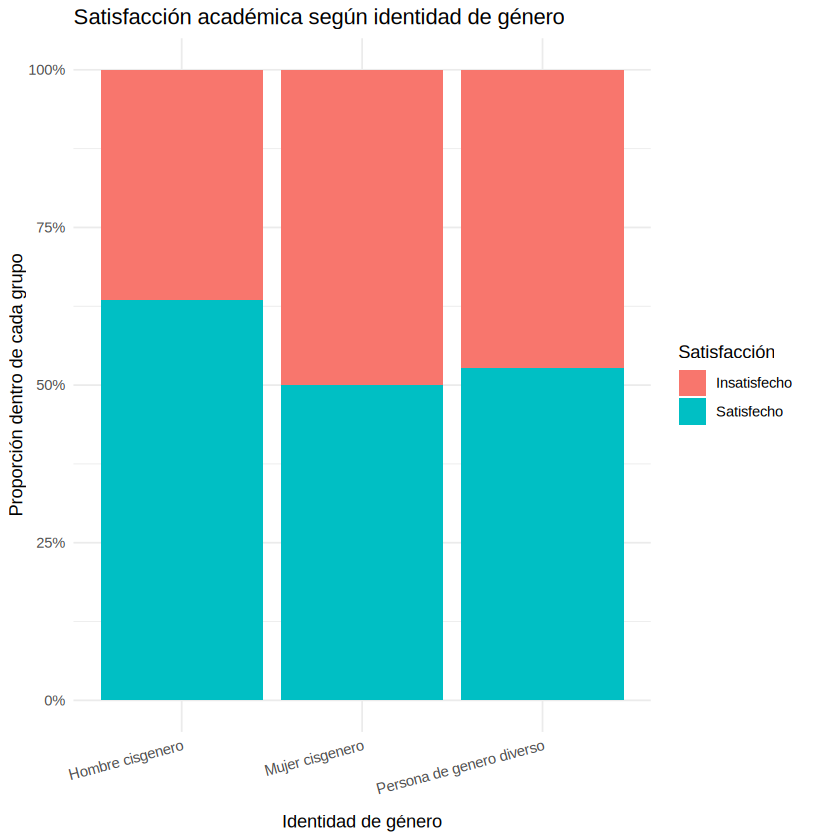

In [15]:
# Gráfico descriptivo de proporciones dentro de cada identidad de género
ggplot(cruce, aes(x = identidad_genero_r,
                  fill = ea_05_satisfaccion_rendimiento_academico_r)) +
  geom_bar(position = "fill") +
  scale_y_continuous(labels = percent_format()) +
  labs(title = "Satisfacción académica según identidad de género",
       x = "Identidad de género", y = "Proporción dentro de cada grupo",
       fill = "Satisfacción") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 15, hjust = 1))


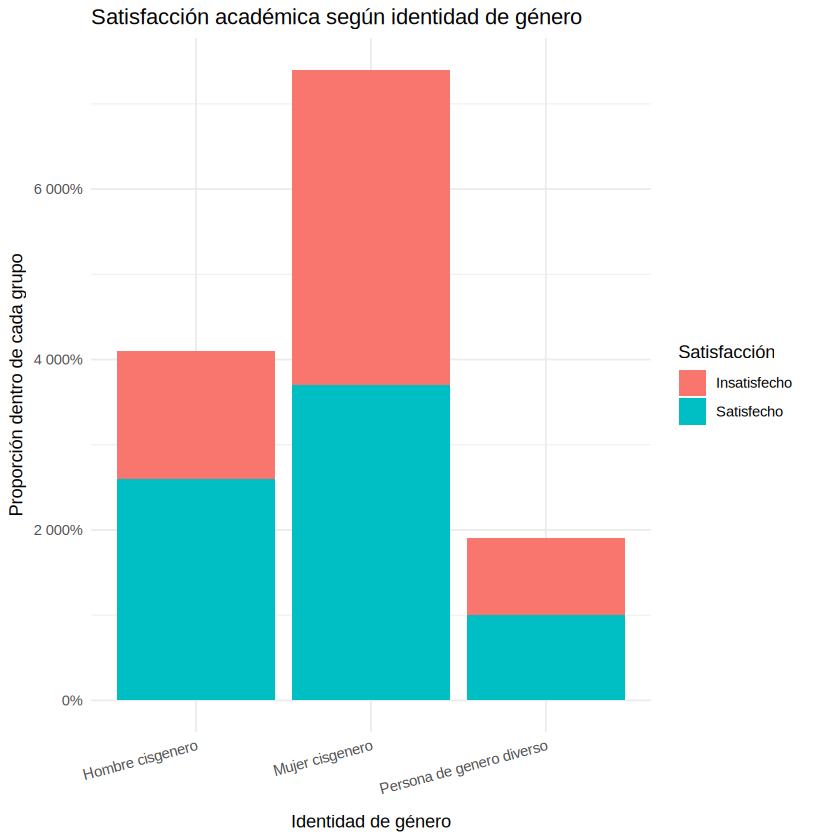

In [16]:
# Gráfico descriptivo de proporciones dentro de cada identidad de género
ggplot(cruce, aes(x = identidad_genero_r,
                  fill = ea_05_satisfaccion_rendimiento_academico_r)) +
  geom_bar(position = "stack") +
  scale_y_continuous(labels = percent_format()) +
  labs(title = "Satisfacción académica según identidad de género",
       x = "Identidad de género", y = "Proporción dentro de cada grupo",
       fill = "Satisfacción") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 15, hjust = 1))

#### ¿Cómo leer e interpretar lo anterior?

**Interpretación del gráfico:** `position = "fill"` representa proporciones dentro de cada grupo; no representa el número absoluto de estudiantes. Sin embargo, esta diferencia visual no demuestra por sí sola una asociación estadísticamente significativa.

Al cambiar position = "fill" por position = "stack", cambia la forma en que se representan los datos:
- position = "fill": muestra las proporciones dentro de cada grupo. Todas las barras tienen la misma altura (100 %), independientemente de la cantidad de estudiantes que las componen.
- position = "stack": muestra las frecuencias absolutas. La altura de cada barra representa la cantidad total de estudiantes del grupo y sus segmentos indican la cantidad de casos de cada categoría.

Las frecuencias nos permiten responder ¿cuántos estudiantes?, mientras que las proporciones nos permiten responder ¿qué porcentaje del grupo representan?

In [17]:
# Prueba χ² y sus valores esperados
chi_genero <- suppressWarnings(chisq.test(tabla_genero_satisfaccion, correct = FALSE))
chi_genero
round(chi_genero$expected, 2)
any(chi_genero$expected < 5)



	Pearson's Chi-squared test

data:  tabla_genero_satisfaccion
X-squared = 1.9448, df = 2, p-value = 0.3782


,Insatisfecho,Satisfecho
Hombre cisgenero,18.66,22.34
Mujer cisgenero,33.69,40.31
Persona de genero diverso,8.65,10.35


[1] FALSE

#### Cómo leer e interpretar lo anterior

**Lectura de χ²:** `chisq.test()` contrasta la hipótesis nula de independencia. `$expected` muestra los conteos que esperaríamos si no hubiera asociación. Comparamos observados y esperados y revisamos los conteos esperados antes de decidir qué prueba informar.

#### **¿Rechazamos la hipótesis nula? ¿Hay asociación o no?**
- Menor a 0,05 no hay asociación
- Mayor a 0,05 hay asociación

#### ¿Qué devuelve `$expected`?

Devuelve una tabla con las frecuencias esperadas de cada celda, es decir, la cantidad de casos que esperaríamos encontrar si no existiera una asociación entre las variables (si la hipótesis nula fuera cierta).

#### ¿Qué significa que alguna frecuencia esperada sea inferior a 5?

Significa que, bajo el supuesto de independencia, esperaríamos encontrar menos de cinco casos en alguna celda de la tabla. Esto puede afectar la fiabilidad del valor p obtenido mediante la prueba de Chi-cuadrado.

Sin embargo, tener una frecuencia esperada inferior a 5 no invalida automáticamente la prueba. Como criterio habitual, se recomienda que al menos el 80 % de las celdas tenga frecuencias esperadas iguales o superiores a 5 y que ninguna sea inferior a 1.

In [18]:
# Decisión pedagógica según la regla revisada en Clase 10
if (any(chi_genero$expected < 5)) {
  prueba_genero <- fisher.test(tabla_genero_satisfaccion)
  cat("Se aplicó test exacto de Fisher.\n")
} else {
  prueba_genero <- chisq.test(tabla_genero_satisfaccion, correct = FALSE)
  cat("Se aplicó prueba χ².\n")
}
print(prueba_genero)
cat("p-valor:", prueba_genero$p.value, "\n")


Se aplicó prueba χ².

	Pearson's Chi-squared test

data:  tabla_genero_satisfaccion
X-squared = 1.9448, df = 2, p-value = 0.3782

p-valor: 0.3781704 


#### ¿Cómo leer e interpretar lo anterior?

**Interpretación de Fisher:** cuando hay celdas con frecuencias esperadas pequeñas, el test exacto de Fisher es una alternativa. Si el valor p es menor que 0,05, se rechaza la hipótesis nula; de lo contrario, no se rechaza. Ninguno de estos resultados demuestra causalidad.

- Menor a 0,05 no hay asociación
- Mayor a 0,05 hay asociación

### Ejercicio:
**Interpreta el resultado.** Con α = 0,05, ¿rechazas o no rechazas H₀? ¿Qué permite concluir el valor p? ¿Por qué no puedes afirmar que la identidad de género *causa* la satisfacción académica?

<details>
<summary><b>Ver respuesta esperada y orientaciones</b></summary>

Busca el nombre de la prueba aplicada y el `p-value` o `p-valor` en la salida. Si p es menor que 0,05, rechaza H₀: hay evidencia de asociación entre identidad de género y satisfacción académica. Si p es igual o mayor, no rechaces H₀: la evidencia es insuficiente. La prueba evalúa asociación, no causalidad; no permite establecer que una variable produzca cambios en la otra.

</details>

### 2.4. Segundo ejemplo: carga académica y satisfacción

Repetimos la secuencia anterior con otro cruce real. **Variable de agrupación:** `ea_03_descripcion_carga_academica`. **Variable de resultado:** `ea_05_satisfaccion_rendimiento_academico_r`. **H₀:** no existe asociación entre carga académica percibida y satisfacción. **H₁:** existe asociación.

Compara las frecuencias observadas con las esperadas, después interpreta el valor p sin atribuir causalidad.


### 2.5. Aplicación del segundo cruce categórico


In [19]:
tabla_carga_satisfaccion <- table(
  base$ea_03_descripcion_carga_academica,
  base$ea_05_satisfaccion_rendimiento_academico_r
)
tabla_carga_satisfaccion
esperados_carga <- suppressWarnings(
  chisq.test(tabla_carga_satisfaccion, correct = FALSE)
)$expected
round(esperados_carga, 2)
if (any(esperados_carga < 5)) {
  resultado_carga <- fisher.test(tabla_carga_satisfaccion)
  cat("Test exacto de Fisher\n")
} else {
  resultado_carga <- chisq.test(tabla_carga_satisfaccion, correct = FALSE)
  cat("Prueba χ²\n")
}
resultado_carga


            
             Insatisfecho Satisfecho
  Ligera                5          9
  Moderada             32         29
  Muy pesada            7          3
  Pesada               17         32

,Insatisfecho,Satisfecho
Ligera,6.37,7.63
Moderada,27.77,33.23
Muy pesada,4.55,5.45
Pesada,22.31,26.69


Test exacto de Fisher



	Fisher's Exact Test for Count Data

data:  tabla_carga_satisfaccion
p-value = 0.09743
alternative hypothesis: two.sided


#### ¿Cómo leer e interpretar lo anterior?

**Interpretación del segundo cruce:** aquí cambian las variables, pero no el procedimiento: tabla observada → frecuencias esperadas → elección de χ² o Fisher → interpretación del valor p. La carga académica percibida y la satisfacción son categóricas, no notas numéricas.

- Menor a 0,05 no hay asociación
- Mayor a 0,05 hay asociación

# **Pruebas de *t* de Student y Test de ANOVA**: comparar medias entre grupos

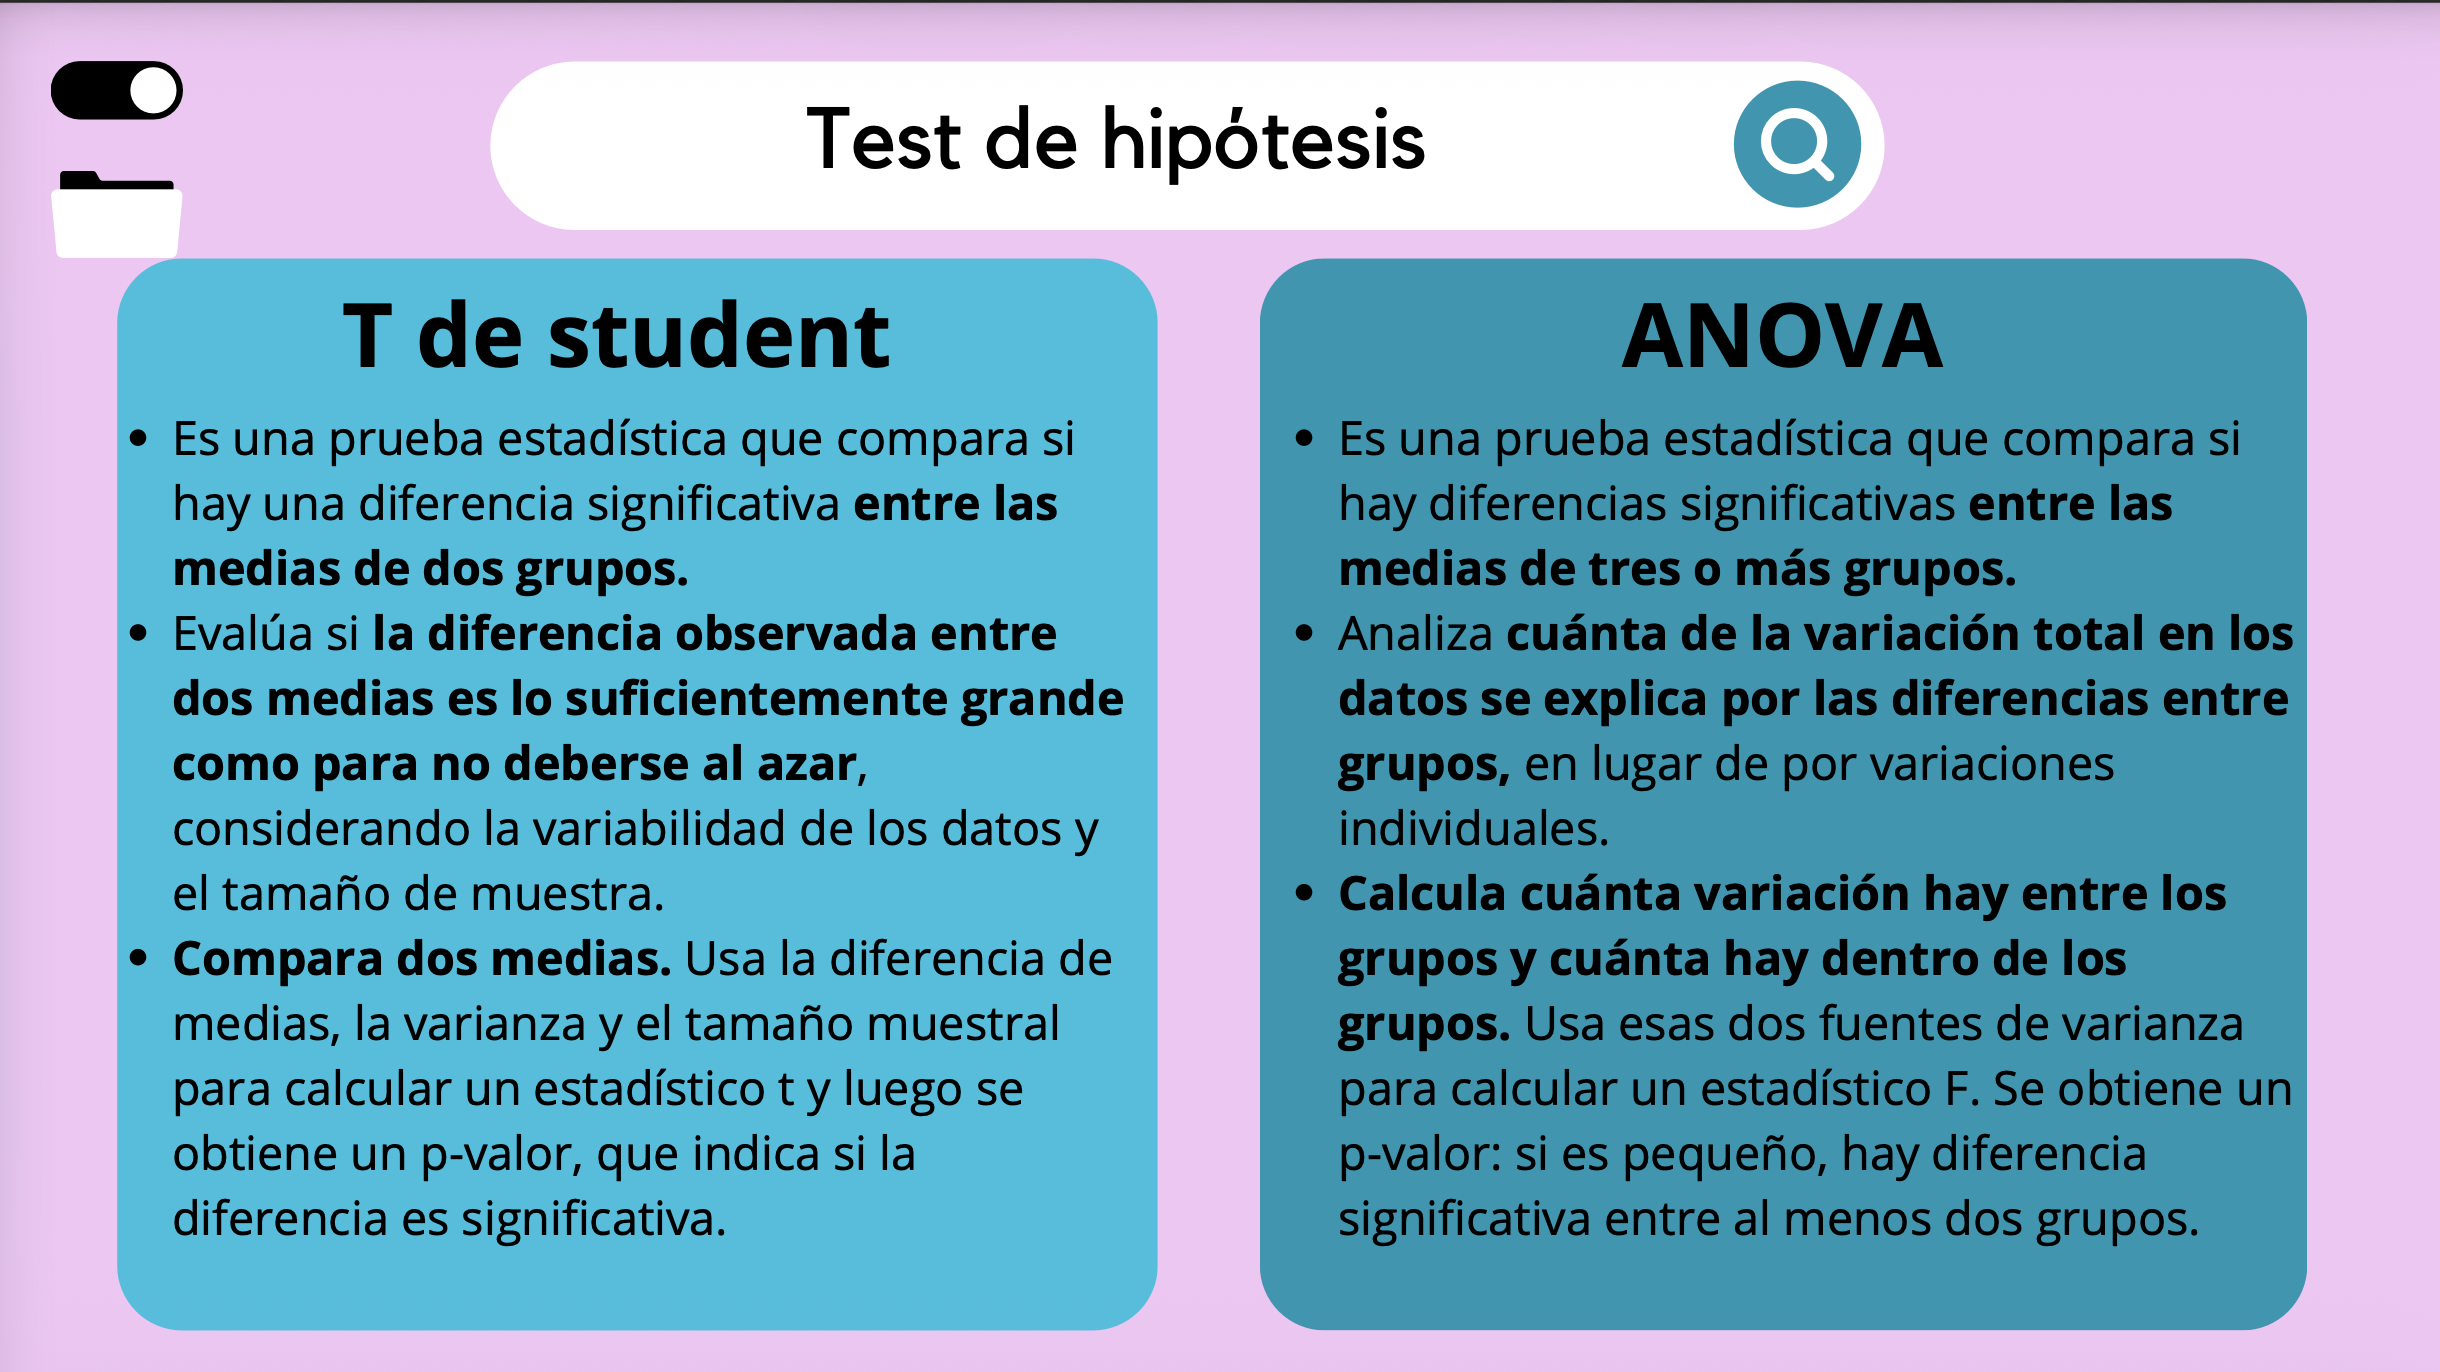

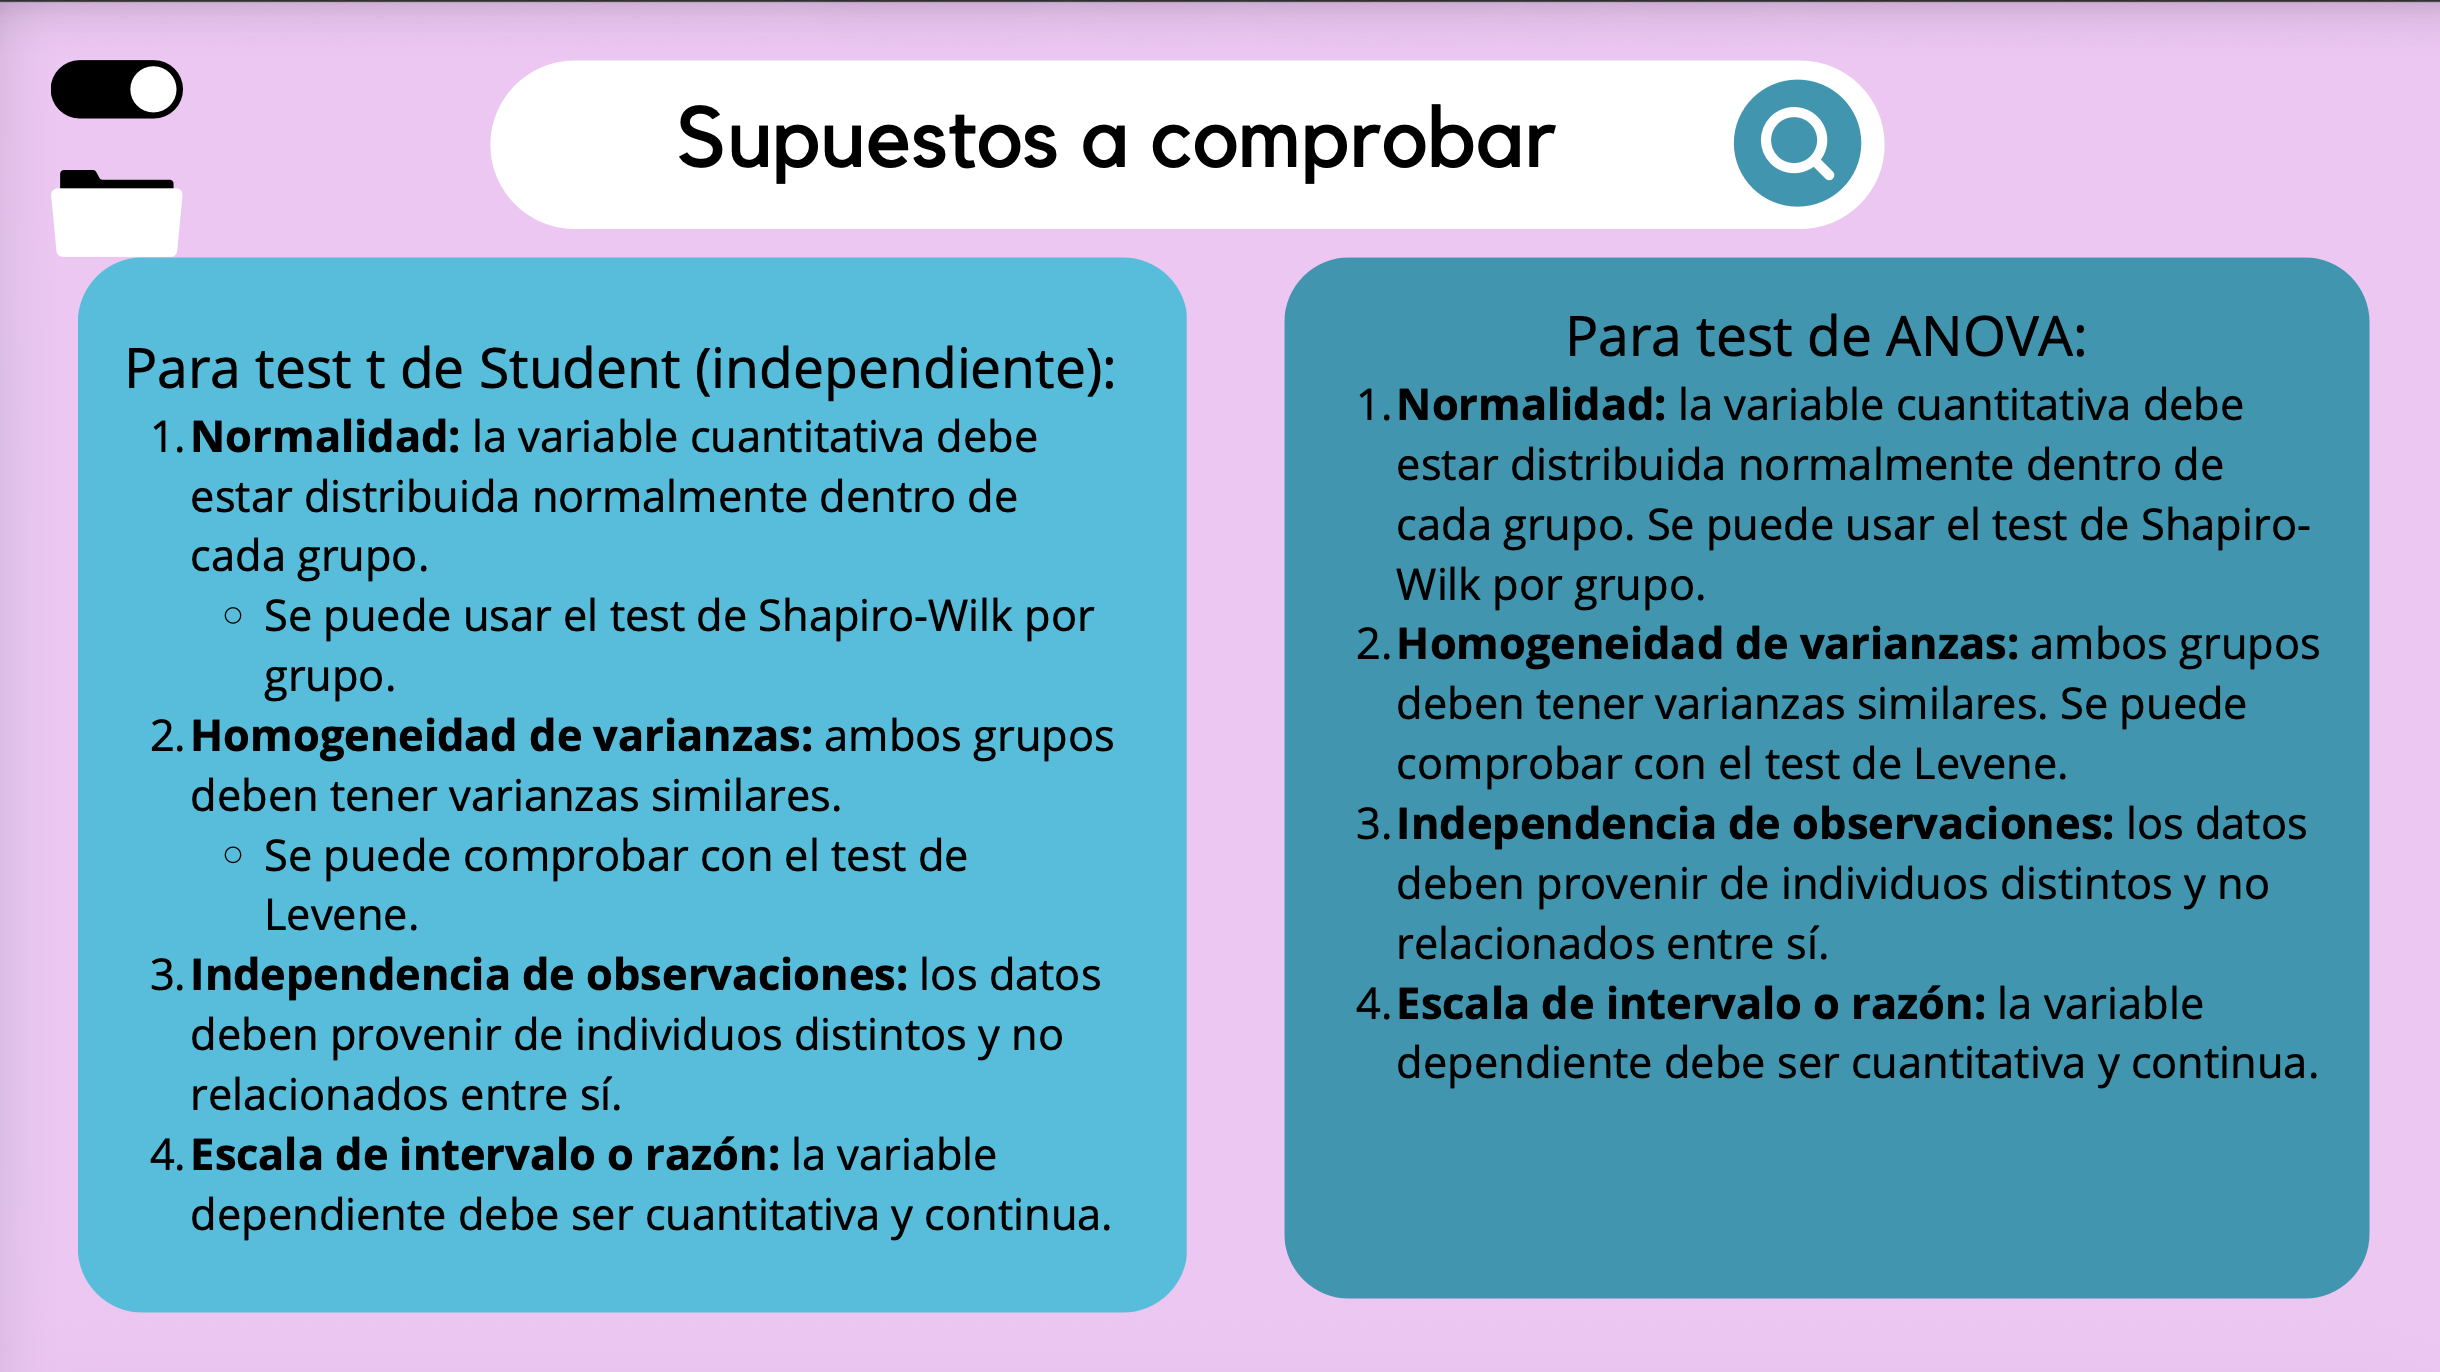

## **Prueba *t* de Student**: comparación de medias entre **dos grupos**

### 3.1. ¿Qué es y para qué sirve?

La prueba *t* permite contrastar si **dos grupos independientes tienen la misma media poblacional** de una variable numérica. En nuestro ejemplo comparamos `ma_02` entre dos categorías de `identidad_genero_r`.

**Variable independiente:** identidad de género, seleccionando dos grupos. **Variable dependiente:** `ma_02`, numérica.

**H₀:** las medias poblacionales de `ma_02` son iguales en ambos grupos. **H₁:** las medias son diferentes.

### 3.2. Supuestos que debemos considerar

1. Las observaciones de distintas personas deben ser independientes.
2. La variable de resultado debe ser numérica y los grupos deben ser dos y mutuamente excluyentes.
3. Para la prueba clásica se supone una distribución aproximadamente normal dentro de cada grupo, especialmente importante en muestras pequeñas.
4. La *t* clásica de Student supone varianzas iguales entre grupos. La variante **Welch**, que también aparece en la Clase 10, no requiere esa igualdad y es la opción predeterminada de `t.test()` en R.

Un gráfico de caja ayuda a describir la distribución, pero no demuestra por sí solo que se cumplan los supuestos.


### 3.3. Ejemplo guiado: comparar dos grupos

Comenzaremos revisando el tipo de `ma_02`, seleccionaremos dos categorías reales y calcularemos las medias antes de aplicar la prueba. La fórmula `ma_02 ~ identidad_genero_r` indica que la variable numérica está a la izquierda y el factor de agrupación a la derecha.


In [ ]:
# Revisar la variable y preparar dos grupos existentes
class(base$ma_02)
table(base$identidad_genero_r, useNA = "ifany")
datos_t <- base %>%
  filter(identidad_genero_r %in% c("Hombre cisgenero", "Mujer cisgenero"),
         !is.na(ma_02)) %>%
  mutate(identidad_genero_r = factor(identidad_genero_r))

datos_t %>% group_by(identidad_genero_r) %>%
  summarise(n = n(), media = mean(ma_02), desviacion = sd(ma_02), .groups = "drop")


#### ¡Cómo leer e interpretar lo anterior?

**Preparación para la prueba t:** `ma_02` es numérica en esta base; `identidad_genero_r` contiene tres categorías, pero para esta comparación se seleccionan **dos grupos reales**. `factor()` indica a R que la variable define grupos. Comprueba el número de casos por grupo.

In [ ]:
ggplot(datos_t, aes(x = identidad_genero_r, y = ma_02,
                    fill = identidad_genero_r)) +
  geom_boxplot(width = 0.55) +
  labs(title = "Distribución de ma_02 por identidad de género",
       x = "Identidad de género", y = "ma_02") +
  guides(fill = "none") + theme_minimal()


#### ¿Cómo leer e interpretar lo anterior?

**Interpretación del boxplot:** la línea central representa la mediana; la caja muestra el 50 % central. El gráfico describe diferencias y dispersión, pero no reemplaza la prueba de hipótesis.

### Ejercicio:
**Comprende el código.** ¿Por qué filtramos exactamente dos categorías? ¿Qué pasaría si intentáramos incluir los tres grupos en una única prueba *t*? ¿Por qué el boxplot es descriptivo y no sustituye la prueba de hipótesis?

<details>
<summary><b>Ver respuesta esperada y orientaciones</b></summary>

La prueba t para grupos independientes compara dos medias. Si se incluyen tres categorías en la fórmula de `t.test()`, R genera un error porque el factor debe tener exactamente dos niveles; para comparar los tres grupos corresponde ANOVA. El boxplot describe medianas y dispersión, pero no calcula el valor p de la comparación de medias.

</details>

### ¿Cómo leeremos la prueba *t*?

En la salida identifica las **medias estimadas por grupo**, el **estadístico t**, el **valor p** y el **intervalo de confianza** para la diferencia de medias. Con α = 0,05, un valor p inferior a 0,05 permite rechazar la hipótesis de igualdad de medias.

Si el valor p no es inferior a 0,05, **no tenemos evidencia suficiente para rechazar H₀**; eso no demuestra que las medias sean idénticas. Tampoco significa que pertenecer a un grupo cause un cambio en `ma_02`.


In [ ]:
# Por defecto t.test() en R aplica la versión de Welch
prueba_t_welch <- t.test(ma_02 ~ identidad_genero_r, data = datos_t)
prueba_t_welch

# Versión de Student con varianzas iguales (comparación incluida en Clase 10)
prueba_t_student <- t.test(ma_02 ~ identidad_genero_r,
                          data = datos_t, var.equal = TRUE)
prueba_t_student


#### ¿Cómo leer e interpretar lo anterior?

**Interpretación de la prueba t:** lee las medias de cada grupo, el intervalo de confianza y el valor p. `t.test()` usa Welch por defecto; `var.equal = TRUE` solicita la versión con varianzas iguales. La hipótesis nula es igualdad de medias entre los dos grupos. Una diferencia estadística no implica que la identidad de género cause el resultado.

### Ejercicio:
**Modifica e interpreta.** Identifica la fórmula `ma_02 ~ identidad_genero_r`: ¿qué variable es numérica y cuál define los grupos? Compara los valores p de Welch y Student. ¿Qué cambia cuando `var.equal = TRUE`? No afirmes causalidad a partir de la comparación.

<details>
<summary><b>Ver respuesta esperada y orientaciones</b></summary>

`ma_02` es la variable numérica (resultado) y `identidad_genero_r` define los grupos. Welch no exige igualdad de varianzas; `var.equal = TRUE` aplica la versión clásica de Student, que sí la supone.

**Tip:** compara `p-value` en ambas salidas y revisa si la decisión respecto de H₀ cambia con α = 0,05. Las medias estimadas aparecen en `sample estimates`. Ninguna de las pruebas establece causalidad.

</details>

## **ANOVA**: comparación de medias entre **tres o más grupos**

### 4.1. ¿Qué es ANOVA?

ANOVA significa **análisis de varianza**. Permite evaluar si las medias de una variable numérica son iguales en **tres o más grupos**. Aunque compara medias, utiliza la relación entre la variabilidad **entre grupos** y la variabilidad **dentro de los grupos**, resumida en el estadístico F.

**Variable independiente:** `identidad_genero_r`, tres categorías. **Variable dependiente:** `ma_02`, numérica.

**H₀:** las tres medias poblacionales son iguales. **H₁:** al menos una media es diferente. Un ANOVA significativo no identifica por sí solo qué grupos difieren.

### 4.2. Supuestos de ANOVA

1. Independencia de las observaciones.
2. Variable de resultado numérica y variable de agrupación categórica, tratada como factor en R.
3. Normalidad aproximada de los errores dentro de los grupos, que la Clase 10 aborda mediante una revisión de normalidad por grupo.
4. Homogeneidad de varianzas entre grupos para el ANOVA clásico. La Clase 10 también menciona la alternativa de Welch cuando las varianzas son desiguales.

**Interpretación:** si p es menor que 0,05, rechazamos la igualdad de todas las medias, pero no afirmamos que la identidad de género cause diferencias en `ma_02`.


### 4.3. Ejemplo guiado: las tres categorías de identidad de género

Primero resumiremos el tamaño y la media de cada grupo, luego observaremos un gráfico de caja y finalmente ejecutaremos `aov()` y `summary()`. Revisar el tamaño de cada grupo es importante antes de interpretar diferencias.


In [ ]:
# La variable de agrupación debe tratarse como factor
base_anova <- base %>%
  filter(!is.na(identidad_genero_r), !is.na(ma_02)) %>%
  mutate(identidad_genero_r = factor(identidad_genero_r))

base_anova %>%
  group_by(identidad_genero_r) %>%
  summarise(n = n(), media = mean(ma_02), SD = sd(ma_02), .groups = "drop")


#### ¿Cómo leer e interpretar lo anterior?

**Lectura del resumen por grupos:** ANOVA compara medias de **tres grupos**. Revisa `n` para cada categoría: un grupo pequeño puede generar estimaciones menos estables. `ma_02` continúa siendo numérica y la identidad de género se convierte en factor.

In [ ]:
ggplot(base_anova, aes(x = identidad_genero_r, y = ma_02,
                        fill = identidad_genero_r)) +
  geom_boxplot(width = 0.6) +
  labs(title = "ma_02 en tres grupos de identidad de género",
       x = "Identidad de género", y = "ma_02") +
  guides(fill = "none") + theme_minimal() +
  theme(axis.text.x = element_text(angle = 15, hjust = 1))


#### ¿Cómo leer e interpretar lo anterior?

**Interpretación del gráfico ANOVA:** compara visualmente centros y dispersión entre las tres categorías. Aunque las cajas se superpongan o separen, la decisión inferencial requiere leer el resultado de `summary(modelo_anova)`.

### Ejercicio:
**Lee el gráfico.** ¿Qué grupo presenta una mediana más alta? ¿Cuál tiene mayor dispersión? ¿Se puede decidir solo mirando el gráfico si la diferencia entre medias es estadísticamente significativa?

<details>
<summary><b>Ver respuesta esperada y orientaciones</b></summary>

Para identificar la mediana más alta, observa la línea horizontal dentro de cada caja. Para comparar la dispersión del 50 % central, fíjate en la altura de las cajas (rango intercuartílico); los bigotes y puntos también aportan información sobre la distribución. No se puede determinar la significación estadística solo con el gráfico: revisa el resultado del ANOVA.

</details>

In [ ]:
# ANOVA tal como se trabaja en la Clase 10
modelo_anova <- aov(ma_02 ~ identidad_genero_r, data = base_anova)
summary(modelo_anova)


#### ¿Cómo leer e interpretar lo anterior?

**Interpretación del ANOVA:** en la fila correspondiente a `identidad_genero_r`, busca `F value` y `Pr(>F)`. Si p < 0,05, existe evidencia de que **al menos una media** difiere; no permite identificar cuál pareja difiere ni demostrar una relación causal. Si p ≥ 0,05, no se rechaza la igualdad de medias.

### Ejercicio:
**Interpreta el ANOVA.** Identifica el estadístico F y el valor p en la salida. Con α = 0,05, ¿rechazas H₀? Si el resultado es significativo, ¿puedes saber solo con esta tabla cuáles grupos difieren entre sí? (La Clase 10 se centra en el contraste global; no agregaremos pruebas posteriores).

<details>
<summary><b>Ver respuesta esperada y orientaciones</b></summary>

En la fila `identidad_genero_r` de `summary(modelo_anova)`, la columna `F value` contiene el estadístico F y `Pr(>F)` contiene el valor p. Si p es menor que 0,05, rechaza H₀: al menos una media poblacional difiere. Si p es igual o mayor, no rechaces H₀. El contraste global no identifica cuáles grupos difieren entre sí.

</details>

## Elegir la prueba e interpretar los resultados

Antes del desafío, recuerda esta secuencia: identificar la pregunta, reconocer el tipo de variable dependiente y de agrupación, formular H₀ y H₁, revisar los supuestos y recién entonces interpretar el valor p.

**Dos variables categóricas:** χ² o Fisher, según las frecuencias esperadas. **Una variable numérica y dos grupos:** *t* de Student o Welch. **Una variable numérica y tres grupos:** ANOVA, considerando sus supuestos.


### 5.1. Desafío integrador: elegir y justificar la prueba


### Ejercicio:
**Elige y fundamenta.**

1. Asociación entre `ea_03_descripcion_carga_academica` y `ea_05_satisfaccion_rendimiento_academico_r`. ¿χ² o Fisher? ¿Qué debes revisar primero?
2. Comparación de la media de `ma_02` entre **Hombre cisgenero** y **Mujer cisgenero**. ¿Qué prueba corresponde?
3. Comparación de la media de `ma_02` entre las **tres** categorías de `identidad_genero_r`. ¿Qué prueba corresponde?
4. ¿Por qué un valor p mayor o igual a 0,05 no demuestra que H₀ sea verdadera?
5. Escribe una conclusión breve, indicando prueba, variables, valor p, decisión y límites de interpretación.

<details>
<summary><b>Ver respuesta esperada y orientaciones</b></summary>

1. χ² o Fisher, porque ambas variables son categóricas. Revisa primero las frecuencias esperadas; según la regla práctica del código, si alguna es inferior a 5, utiliza Fisher.
2. Prueba t para dos grupos independientes: Welch por defecto, o Student si se supone igualdad de varianzas.
3. ANOVA, porque se compara una variable numérica entre tres grupos.
4. Un valor p igual o mayor que 0,05 indica evidencia insuficiente para rechazar H₀, no que esta sea verdadera.
5. **Modelo de conclusión:** «Se aplicó [prueba] para analizar [variables]. Se obtuvo p = [valor]. Con α = 0,05, [se rechaza/no se rechaza] H₀. Los resultados [aportan/no aportan] evidencia suficiente de [asociación/diferencia de medias]. No permiten establecer causalidad». Completa con la salida real.

</details>

## Para cerrar

**χ² / Fisher:** asociación entre dos variables categóricas; revisar frecuencias esperadas.

***t* de Student:** comparación de una media numérica entre dos grupos; la Clase 10 también contrasta la variante de Welch.

**ANOVA:** contraste global de medias numéricas entre tres grupos.

**Regla transversal:** describir los datos, comprobar el tipo de variable, interpretar el valor p y evitar afirmaciones causales.